# ANN errors

Where the canonical ANN (`models/ann_wind_augmented_no_thrust_no_delay.keras`) fails, using the same trajectory-grouped split (seed 42, 33% test) as `data_correction_and_model_training.ipynb`. Error is the median per-trajectory angular error (deg).

- **A.** Error vs. mean slip angle (held-out trajectories)
- **B.** Error vs. five-model ensemble mean resultant length $R$ (held-out trajectories)
- **C.** Error for trajectories inside vs. outside the training set

In [1]:
import os, sys, random
import numpy as np
import pandas as pd
import keras
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.model_selection import GroupShuffleSplit
sys.path.insert(0, os.path.abspath('../utils'))
from utils import (circular_distance, pull_out_individual_trajectories,
                   augment_with_time_delay_embedding, register_geodesic_loss)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
data = pd.read_csv('../pipelinedata/05_final/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv')

# same trajectory-grouped split as the training notebook
traj_ids = data['trajec_objid'].unique()
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=RANDOM_SEED)
                           .split(np.zeros((len(traj_ids), 1)), groups=traj_ids))
train_ids, test_ids = set(traj_ids[train_idx]), set(traj_ids[test_idx])

trajs = pull_out_individual_trajectories(data, min_traj_length=12)
train_trajs = [t for t in trajs if t['trajec_objid'].iloc[0] in train_ids]
test_trajs  = [t for t in trajs if t['trajec_objid'].iloc[0] in test_ids]
print(len(train_trajs), 'train trajectories,', len(test_trajs), 'test trajectories')

I0000 00:00:1791842393.081289  341357 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791842393.084895  341357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791842393.372392  341357 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791842395.829040  341357 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791842395.830736  341357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Detected 3422 trajectories.


3340 trajectories with more than 12 timesteps.
2235 train trajectories, 1105 test trajectories


In [2]:
INPUTS = ['groundspeed', 'groundspeed_angle', 'airspeed', 'airspeed_angle']
KEEP = ['heading_angle_x', 'heading_angle_y', 'trajec_objid']

def embed(tl):
    return augment_with_time_delay_embedding(tl, wind_augment=False, wrap_angles=False, time_window=1,
                                             input_names=INPUTS, output_names=KEEP, direction='backward')

def per_trajectory_error(model, tl):
    emb = embed(tl)
    pred = model.predict(emb.iloc[:, :len(INPUTS)].values, verbose=0)
    y = emb[['heading_angle_x', 'heading_angle_y']].values
    err = np.degrees(circular_distance(np.arctan2(y[:, 1], y[:, 0]), np.arctan2(pred[:, 1], pred[:, 0])))
    return pd.DataFrame({'trajec_objid': emb['trajec_objid'].values, 'err': err}).groupby('trajec_objid')['err'].median()

register_geodesic_loss()
model = keras.models.load_model('../models/ann_wind_augmented_no_thrust_no_delay.keras')
err_train = per_trajectory_error(model, train_trajs)
err_test  = per_trajectory_error(model, test_trajs)
print(f'median error  train: {err_train.median():.2f} deg   test: {err_test.median():.2f} deg')

E0000 00:00:1791842398.654136  341357 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


median error  train: 5.08 deg   test: 5.35 deg


In [3]:
# mean |slip angle| (body heading vs. airspeed direction) per trajectory
slip = {}
for t in trajs:
    slip.setdefault(t['trajec_objid'].iloc[0],
                    np.degrees(np.abs(circular_distance(t['heading_angle'].values, t['airspeed_angle'].values))).mean())
slip = pd.Series(slip, name='slip')
test_df = err_test.rename('err').to_frame().join(slip)

# five-seed ensemble mean resultant length (saved by the training notebook for the test set)
ens = pd.read_csv('../pipelinedata/05_final/ann_ensemble_agreement.csv').set_index('trajec_objid')
ens_df = ens[['R']].join(err_test.rename('err'), how='inner')   # recompute err with the canonical model loaded here
rho_slip = spearmanr(test_df['slip'], test_df['err'])
rho_R    = spearmanr(ens_df['R'], ens_df['err'])
print(f'slip:  rho = {rho_slip.statistic:.3f}  (n = {len(test_df)})')
print(f'R:     rho = {rho_R.statistic:.3f}  (n = {len(ens_df)})')

slip:  rho = 0.781  (n = 1099)
R:     rho = -0.528  (n = 1099)


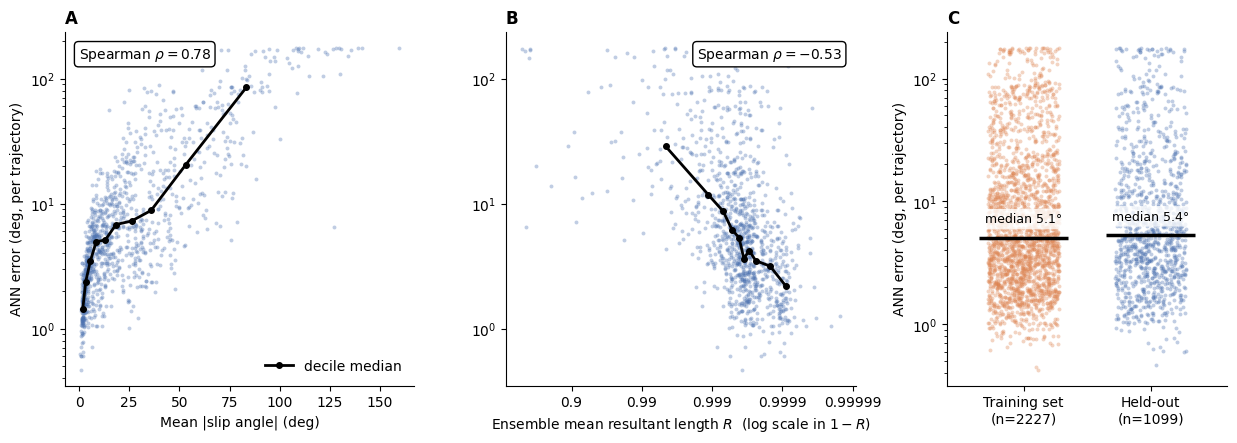

In [4]:
BLUE, ORANGE, GREY = '#4C72B0', '#DD8452', '#555555'
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.8], wspace=0.28))

def binned_median(ax, x, y, n=10, color='black'):
    b = pd.qcut(x, n, duplicates='drop')
    g = pd.DataFrame({'x': x, 'y': y, 'b': b}).groupby('b', observed=True).agg(x=('x', 'median'), y=('y', 'median'))
    ax.plot(g['x'], g['y'], '-o', color=color, lw=2, ms=4, label='decile median')

# A: error vs slip angle
ax = axes[0]
ax.scatter(test_df['slip'], test_df['err'], s=8, alpha=0.35, color=BLUE, lw=0, rasterized=True)
binned_median(ax, test_df['slip'], test_df['err'])
ax.set_yscale('log'); ax.set_xlabel('Mean |slip angle| (deg)'); ax.set_ylabel('ANN error (deg, per trajectory)')
ax.text(0.04, 0.96, rf'Spearman $\rho = {rho_slip.statistic:.2f}$', transform=ax.transAxes, va='top',
        bbox=dict(boxstyle='round', fc='white', ec='black'))
ax.legend(loc='lower right', frameon=False); ax.set_title('A', loc='left', fontweight='bold')

# B: error vs ensemble resultant length (R is crowded near 1, so plot 1 - R on a log axis, agreement to the right)
ax = axes[1]
d = (1 - ens_df['R']).clip(lower=1e-6)
ax.scatter(d, ens_df['err'], s=8, alpha=0.35, color=BLUE, lw=0, rasterized=True)
binned_median(ax, d, ens_df['err'])
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ticks = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
ax.set_xticks(ticks); ax.set_xticklabels([f'{1 - t:g}' for t in ticks]); ax.minorticks_off()
ax.set_xlabel('Ensemble mean resultant length $R$  (log scale in $1-R$)')
ax.text(0.96, 0.96, rf'Spearman $\rho = {rho_R.statistic:.2f}$', transform=ax.transAxes, va='top', ha='right',
        bbox=dict(boxstyle='round', fc='white', ec='black'))
ax.set_title('B', loc='left', fontweight='bold')

# C: trained-on vs held-out trajectories
ax = axes[2]
rng = np.random.default_rng(0)
for i, (name, e, c) in enumerate([('Training set', err_train, ORANGE), ('Held-out', err_test, BLUE)]):
    ax.scatter(i + rng.uniform(-0.28, 0.28, len(e)), e, s=8, alpha=0.35, color=c, lw=0, rasterized=True)
    ax.hlines(e.median(), i - 0.35, i + 0.35, color='black', lw=2.5)
    ax.text(i, e.median() * 1.25, f'median {e.median():.1f}°', ha='center', va='bottom', fontsize=9,
            bbox=dict(boxstyle='round', fc='white', ec='none', alpha=0.8))
ax.set_yscale('log'); ax.set_xlim(-0.6, 1.6)
ax.set_xticks([0, 1]); ax.set_xticklabels([f'Training set\n(n={len(err_train)})', f'Held-out\n(n={len(err_test)})'])
ax.set_ylabel('ANN error (deg, per trajectory)'); ax.set_title('C', loc='left', fontweight='bold')

for a in axes: a.spines[['top', 'right']].set_visible(False)
os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/ann_errors.pdf', bbox_inches='tight')
fig.savefig('../figures/ann_errors.png', dpi=300, bbox_inches='tight')
plt.show()